In [2]:
import pandas as pd
from pathlib import Path

files = sorted(Path("../data/raw").glob("*.csv"))
df = pd.concat(pd.read_csv(f, parse_dates=["SETTLEMENTDATE"]) for f in files)
df = df.set_index("SETTLEMENTDATE").sort_index().drop(columns=["REGION", "PERIODTYPE"])
rrp = df["RRP"]

print(df.index.min(), df.index.max(), len(df))
print(df.index.to_series().diff().value_counts())
df.isna().sum()

2023-11-01 00:05:00 2025-11-01 00:00:00 210528
SETTLEMENTDATE
0 days 00:05:00    210527
Name: count, dtype: int64


TOTALDEMAND    0
RRP            0
dtype: int64

No missing or duplicates intervals across the two years

## Task definition
- Every day at midnight (market time), forecast all 288 five-minute prices for the next 24 hours.
- Test period: 1 Aug 2025 to 31 Oct 2025. I won't use this period to tune anything. Every model gets scored on it.
- Metric: MAE in AUD/MWh, reported overall, for normal intervals, and for spikes (price above 300).

## Three baselines
- yesterday: same time yesterday
- last_week: same time, same weekday last week
- median_7d: median of the same time across the last 7 days, which smooths out one-off weird days

In [11]:
DAY = 288 # 5-minute intervals per day

baselines = pd.DataFrame({
    "actual": rrp,
    "yesterday": rrp.shift(DAY),
    "last_week": rrp.shift(7 * DAY),
    "median_7d": pd.concat([rrp.shift(k * DAY) for k in range(1,8)], axis=1).median(axis=1),
})

## Evaluation

In [15]:
def evaluate(actual: pd.Series, forecast: pd.Series, spike_threshold:float = 300) -> dict:
    """ MAE overall, on normal intervals, and on spikes. """
    mask = forecast.notna()
    actual, forecast = actual[mask], forecast[mask]
    error = (actual - forecast).abs()
    spike = actual > spike_threshold
    return {
        "MAE": error.mean(),
        "MAE normal": error[~spike].mean(),
        "MAE spike": error[spike].mean(),
        "n spikes": int(spike.sum()),
    }

test = baselines.loc["2025-08-01":]
results = pd.DataFrame({
    name: evaluate(test["actual"], test[name])
    for name in ["yesterday", "last_week", "median_7d"]
}).T.round(1)
results["n spikes"] = results["n spikes"].astype(int)
results


,MAE,MAE normal,MAE spike,n spikes
yesterday,64.0,61.5,319.2,259
last_week,80.3,77.4,374.5,259
median_7d,58.4,55.3,370.5,259


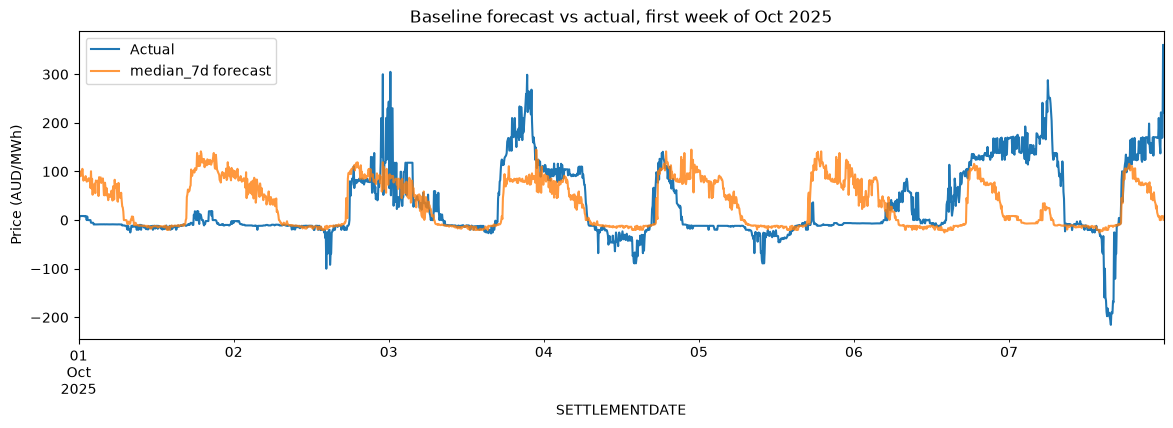

In [16]:
week = test.loc["2025-10-01":"2025-10-07"]
ax = week["actual"].plot(figsize=(14, 4), label="Actual")
week["median_7d"].plot(ax=ax, label="median_7d forecast", alpha=0.8)
ax.set_ylabel("Price (AUD/MWh)")
ax.set_title("Baseline forecast vs actual, first week of Oct 2025")
ax.legend();

## Baseline results

*MAE in AUD/MWh on the test period (1 Aug to 31 Oct 2025). All baselines are scored on the same intervals.*

**Finding:** median_7d is the best baseline, with an MAE of 58.4. This is the number to beat in M2.

**Evidence:**
- median_7d has the lowest overall MAE (58.4) and normal-interval MAE (55.3).
- yesterday is better on spikes (319 vs 370). Spikes seem to come in runs, so yesterday's price carries some of that signal, while the median smooths it away.
- last_week is the worst on every metric (80.3 overall). SA prices follow the weather, which doesn't repeat weekly.
- All three baselines miss spikes badly. They predict normal prices when spikes happen.
- 259 spike intervals (about 1%) only add roughly 4 to the overall MAE, so most of the error comes from normal intervals.

**What this means:**
- M2 target: beat median_7d by at least 15%, so an MAE under 50.
- The biggest gains will come from predicting normal days better, which needs weather data (wind, solar, temperature).
- Recent spike activity might be a useful feature, since spikes cluster.

**From the forecast vs actual plot (1 to 7 Oct 2025):**
- The baseline gets the midday solar trough right almost every day.
- Its biggest errors are evenings. On Oct 1, 2 and 6 it predicted the usual evening rise to 100 to 140, but prices stayed near 0, probably because of wind. On Oct 3 and 4, evening prices were higher than predicted.
- On Oct 7, prices stayed high for most of the day, which the baseline couldn't anticipate.
- Evenings act like a switch: either wind covers them or it doesn't. The baseline averages both cases, so it's wrong either way. A wind forecast should help most here.